In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data (3).csv')
df.head()

,Дата,Склад,Контрагент,Номенклатура,Количество
0,2018-01-04,1,address_0,product_0,4
1,2018-01-04,1,address_0,product_1,4
2,2018-01-04,1,address_0,product_2,5
3,2018-01-04,1,address_0,product_3,10
4,2018-01-04,1,address_0,product_4,2


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Дата          301355 non-null  str  
 1   Склад         301355 non-null  int64
 2   Контрагент    301355 non-null  str  
 3   Номенклатура  301355 non-null  str  
 4   Количество    301355 non-null  int64
dtypes: int64(2), str(3)
memory usage: 20.0 MB


In [6]:
df['Дата'] = pd.to_datetime(df['Дата'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Дата          301355 non-null  datetime64[us]
 1   Склад         301355 non-null  int64         
 2   Контрагент    301355 non-null  str           
 3   Номенклатура  301355 non-null  str           
 4   Количество    301355 non-null  int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 17.2 MB


In [7]:
sales_by_day = df.groupby('Дата')['Количество'].sum()

sales_by_day.head()

Дата
2018-01-04    3734
2018-01-05    3643
2018-01-06    3193
2018-01-07    3298
2018-01-09    4055
Name: Количество, dtype: int64

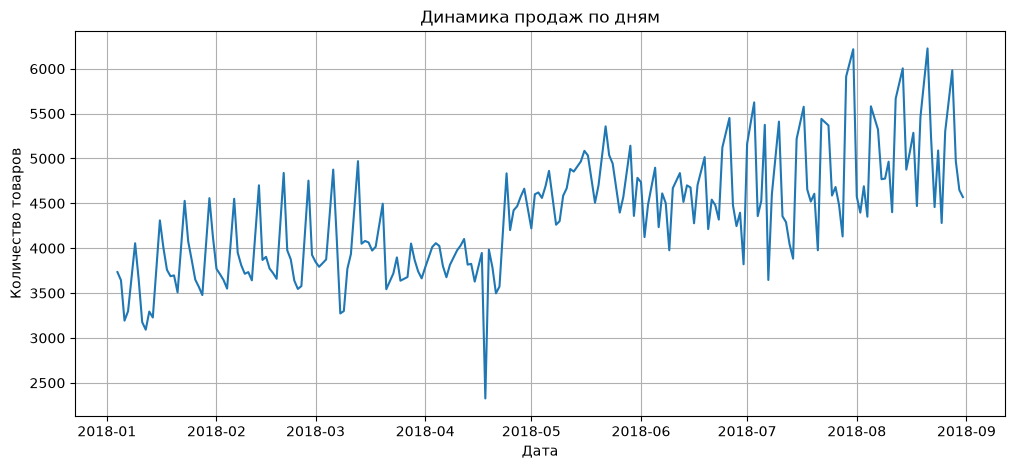

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(sales_by_day.index, sales_by_day.values)

plt.title('Динамика продаж по дням')
plt.xlabel('Дата')
plt.ylabel('Количество товаров')
plt.grid(True)
plt.show()

In [9]:
print('Максимальные продажи за день:')
print(sales_by_day.idxmax(), sales_by_day.max())

print('\nМинимальные продажи за день:')
print(sales_by_day.idxmin(), sales_by_day.min())

Максимальные продажи за день:
2018-08-21 00:00:00 6226

Минимальные продажи за день:
2018-04-18 00:00:00 2326


In [10]:
filtered = df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6, 7, 8])) &
    (df['Дата'].dt.dayofweek == 2)
]

top_products = (
    filtered.groupby('Номенклатура')['Количество']
    .sum()
    .sort_values(ascending=False)
)

print(top_products.head(10))
print('\nСамый продаваемый товар:', top_products.idxmax())
print('Количество:', top_products.max())

Номенклатура
product_1     2267
product_2     2060
product_0     1324
product_3      914
product_6      650
product_4      540
product_22     509
product_5      480
product_13     253
product_15     230
Name: Количество, dtype: int64

Самый продаваемый товар: product_1
Количество: 2267


In [11]:
import pandas as pd

url = (
    "https://archive-api.open-meteo.com/v1/archive"
    "?latitude=51.18&longitude=71.45"
    "&start_date=2018-01-04"
    "&end_date=2018-08-31"
    "&daily=temperature_2m_mean"
    "&timezone=Asia%2FAlmaty"
)

weather_json = pd.read_json(url)

weather = pd.DataFrame({
    'Дата': pd.to_datetime(weather_json['daily']['time']),
    'Температура': weather_json['daily']['temperature_2m_mean']
})

weather.head()

,Дата,Температура
0,2018-01-04,-18.5
1,2018-01-05,-21.5
2,2018-01-06,-19.0
3,2018-01-07,-20.6
4,2018-01-08,-17.6


In [12]:
sales_weather = pd.merge(
    sales_by_day.reset_index(),
    weather,
    on='Дата',
    how='inner'
)

sales_weather.head()

,Дата,Количество,Температура
0,2018-01-04,3734,-18.5
1,2018-01-05,3643,-21.5
2,2018-01-06,3193,-19.0
3,2018-01-07,3298,-20.6
4,2018-01-09,4055,-6.3


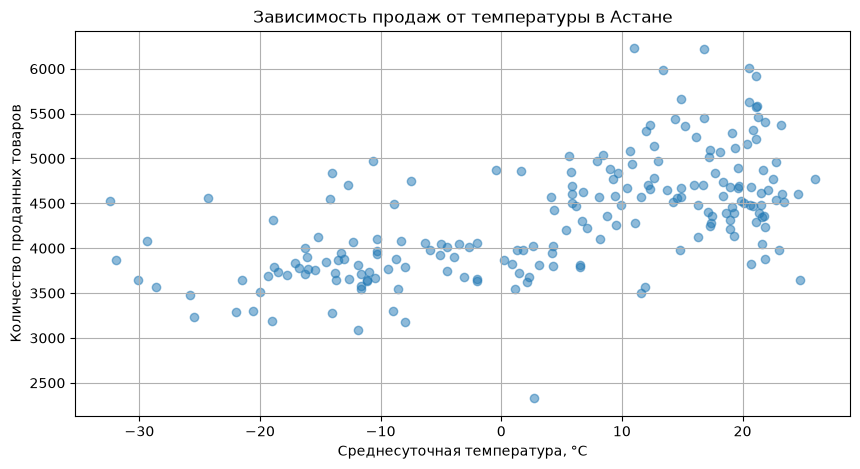

In [13]:
plt.figure(figsize=(10, 5))

plt.scatter(
    sales_weather['Температура'],
    sales_weather['Количество'],
    alpha=0.5
)

plt.title('Зависимость продаж от температуры в Астане')
plt.xlabel('Среднесуточная температура, °C')
plt.ylabel('Количество проданных товаров')
plt.grid(True)
plt.show()

In [14]:
correlation = sales_weather['Температура'].corr(
    sales_weather['Количество']
)

print('Корреляция:', round(correlation, 3))
print('Количество дней:', len(sales_weather))

Корреляция: 0.604
Количество дней: 205


Вывод по анализу температуры и продаж

Для анализа использованы данные о ежедневных продажах и среднесуточной температуре воздуха в Астане за 2018 год.

После объединения данных получено 205 дней наблюдений.

Коэффициент корреляции Пирсона составил 0,604, что указывает на умеренную положительную линейную связь между температурой воздуха и количеством проданных товаров.

На диаграмме рассеяния видно, что при более высоких температурах продажи в среднем выше. Однако на результаты могла повлиять сезонность, поскольку в рассматриваемом периоде одновременно увеличивались и температура, и объёмы продаж.

Заключение: между температурой и продажами обнаружена положительная корреляция, но причинно-следственная связь не доказана.